In [133]:
import pandas as pd
import matplotlib.pyplot as plt
from io import StringIO

In [134]:
with open("bitcoin_tweets1000000.csv", "r", encoding="utf-8", errors="replace") as f:
    text = f.read()

In [135]:
num_errors = text.count("�")
print(f"Anzahl der Encoding-Fehler: {num_errors}")

Anzahl der Encoding-Fehler: 439


In [136]:
df = pd.read_csv(StringIO(text))

C:\Users\johan\AppData\Local\Temp\ipykernel_6576\647184928.py:1: DtypeWarning: Columns (0,5,6,7,8,13) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(StringIO(text))


In [137]:
df.columns

Index(['Unnamed: 0', 'user_name', 'user_location', 'user_description',
       'user_created', 'user_followers', 'user_friends', 'user_favourites',
       'user_verified', 'date', 'text', 'hashtags', 'source', 'is_retweet',
       'cleanText', 'Polarity Score', 'sentiment'],
      dtype='object')

In [138]:
df1=df.value_counts('user_name')

In [139]:
df1

user_name
Brett Murphy          7749
Hoba Bot              7075
BitcoinAgile          4857
Bitcoin updates       4463
CryptoSquawk          4448
                      ... 
Lanaya                   1
Lanang78                 1
Lanang Fauzan            1
LanaCoin.org $LANA       1
🫐📁                       1
Name: count, Length: 194081, dtype: int64

In [140]:
df1.count()

194081

c:\Users\johan\AppData\Local\Programs\Python\Python310\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 128640 (\N{ROCKET}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\johan\AppData\Local\Programs\Python\Python310\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 10024 (\N{SPARKLES}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\johan\AppData\Local\Programs\Python\Python310\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 127477 (\N{REGIONAL INDICATOR SYMBOL LETTER P}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\johan\AppData\Local\Programs\Python\Python310\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 127469 (\N{REGIONAL INDICATOR SYMBOL LETTER H}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\johan\AppData\Local\Programs\Python\Python310\lib\site

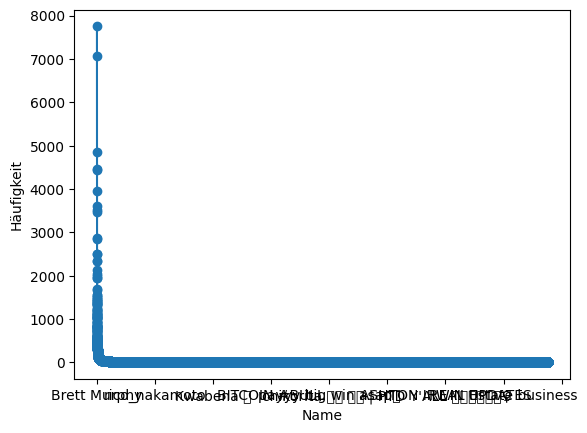

In [141]:
df1.plot(kind="line", marker="o")
plt.xlabel("Name")
plt.ylabel("Häufigkeit")
plt.show()

In [142]:
df1[df1 <= 1].count()

109672

c:\Users\johan\AppData\Local\Programs\Python\Python310\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 128640 (\N{ROCKET}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\johan\AppData\Local\Programs\Python\Python310\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 10024 (\N{SPARKLES}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\johan\AppData\Local\Programs\Python\Python310\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 127477 (\N{REGIONAL INDICATOR SYMBOL LETTER P}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\johan\AppData\Local\Programs\Python\Python310\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 127469 (\N{REGIONAL INDICATOR SYMBOL LETTER H}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\johan\AppData\Local\Programs\Python\Python310\lib\site

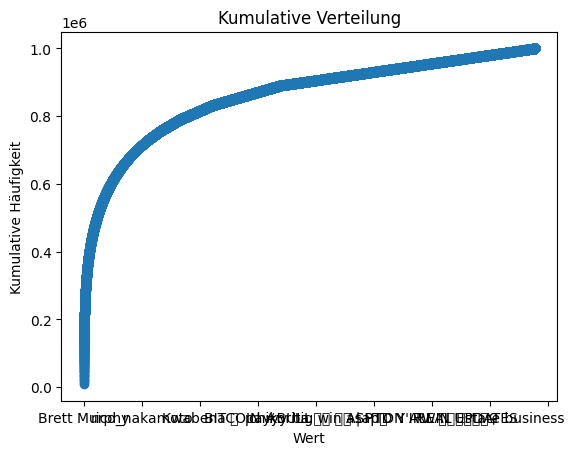

In [143]:
df1.cumsum().plot(kind="line", marker="o")
plt.xlabel("Wert")
plt.ylabel("Kumulative Häufigkeit")
plt.title("Kumulative Verteilung")
plt.show()

In [144]:
df['user_followers']= pd.to_numeric(df['user_followers'], errors='coerce')
df['user_friends']= pd.to_numeric(df['user_friends'], errors='coerce')
df['user_favourites']= pd.to_numeric(df['user_favourites'], errors='coerce')
df['user_verified']= pd.to_numeric(df['user_verified'], errors='coerce')
df['Polarity Score'] = pd.to_numeric(df['Polarity Score'], errors='coerce')
df['sentiment'] = pd.to_numeric(df['sentiment'], errors='coerce')
df['is_retweet'] = pd.to_numeric(df['is_retweet'], errors='coerce')

In [145]:
import ast

def to_unique_hashtag_list(x):
    # Leere Liste, wenn kein String
    if not isinstance(x, str):
        return []

    try:
        lst = ast.literal_eval(x)  # konvertiert "['a','b']" → ['a','b']
    except:
        return []

    if not isinstance(lst, list):
        return []

    # Duplikate entfernen, Reihenfolge behalten
    return list(dict.fromkeys([str(i).strip() for i in lst]))

In [146]:
df["hashtags"] = df["hashtags"].apply(to_unique_hashtag_list)

In [147]:
df_user = df.groupby('user_name').agg({
    'text': lambda x: ' '.join(str(i) for i in x if pd.notnull(i)),
    'user_description': 'first',
    'user_followers': 'mean',
    'user_friends': 'mean',
    'user_favourites': 'mean',
    'user_verified': 'max',
    'hashtags': lambda x: list(dict.fromkeys(tag for lst in x for tag in lst)),
    'is_retweet': ['sum', 'count']  # sum = retweet_count, count = total_tweets
}).reset_index()

df_user.columns = ['user_name', 'text', 'user_description', 'user_followers', 
                   'user_friends', 'user_favourites', 'user_verified', 'hashtags',
                   'retweet_count', 'total_tweets']

df_user['retweet_ratio'] = df_user['retweet_count'] / df_user['total_tweets']

In [148]:
df_user.count()

user_name           194081
text                194081
user_description    162904
user_followers      194078
user_friends        194074
user_favourites     194071
user_verified       166456
hashtags            194081
retweet_count       194081
total_tweets        194081
retweet_ratio       191212
dtype: int64

In [149]:
df_user.columns

Index(['user_name', 'text', 'user_description', 'user_followers',
       'user_friends', 'user_favourites', 'user_verified', 'hashtags',
       'retweet_count', 'total_tweets', 'retweet_ratio'],
      dtype='object')

In [150]:
df_user.to_csv("bitcoin_users.csv", encoding="utf-8", index= False)

In [151]:
df_user.to_parquet("bitcoin_users.parquet", compression="zstd")